# 08 - Live monitoring: anomaly detection, change points and Kalman tracking

Notebooks 04 and 06 diagnosed faults window by window, with fault labels (or physics) to say what
each fault looks like. A twin in service also needs three things the project did not yet have:

1. **Detection without fault labels.** In practice the healthy history is all there is. How far do
   detectors trained on healthy data alone get?
2. **Detection delay.** How quickly is a change caught on a live stream, and how much damage has
   accumulated by then when degradation is gradual?
3. **Tracking.** A running estimate of each health indicator with an uncertainty band, which is what
   "the twin mirrors the asset" means in practice.

Every method here is calibrated on healthy data only and then scored on fault data.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fueltwin import config, features, hydraulics as hy, monitor as mo, plotting as pl, simulate as sm

warnings.filterwarnings("ignore")
pl.use_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 170)
w = features.load_windows(1.0)
R, _ = hy.lofo_residuals(w)
w = pd.concat([w, R], axis=1)
RAW = ["P1", "P2", "P3", "P4", "P5", "Q"]
HC_RUNS = [f"HC-{i}" for i in range(1, 7)]
EMPTY = ["F2-020", "F4-020", "F4-030"]  # settings with no physical effect (notebook 03)

## 1. Anomaly detection trained on healthy data only

Four detectors are fitted on healthy windows and flag anything scoring above the 99.5th percentile
of their training scores. Healthy windows are scored leave-one-healthy-run-out (fit on five runs,
test the sixth). Two feature sets: the raw readings, and the four physics residuals. The column that
matters most is **"physically empty settings"**: F2 20 % and F4 20-30 % produce no hydraulic change, so
a detector that flags them is reacting to something other than a fault.

In [2]:
rows, flags_store = [], {}
for feats, fname in [(RAW, "raw readings"), (hy.RESIDUALS, "physics residuals")]:
    for det in mo.DETECTORS:
        flag = pd.Series(np.nan, index=w.index)
        for hr in HC_RUNS:
            tr = w[(w["condition"] == "HC") & (w["run_id"] != hr)]
            te = w[w["run_id"] == hr]
            s_tr, s_te = mo.anomaly_scores(det, tr[feats], te[feats])
            flag[te.index] = (s_te > np.quantile(s_tr, 0.995)).astype(float)
        tr, te = w[w["condition"] == "HC"], w[w["condition"] != "HC"]
        s_tr, s_te = mo.anomaly_scores(det, tr[feats], te[feats])
        flag[te.index] = (s_te > np.quantile(s_tr, 0.995)).astype(float)
        flags_store[(fname, det)] = flag
        fault = w["condition"] != "HC"
        rows.append({"features": fname, "detector": det,
                     "healthy windows flagged (held-out runs)": flag[w["condition"] == "HC"].mean(),
                     "physically empty settings flagged": flag[w["run_id"].isin(EMPTY)].mean(),
                     "mild settings (10-20 %) flagged": flag[fault & (w["severity"] <= 20) & ~w["run_id"].isin(EMPTY)].mean(),
                     "clear faults (>= 40 %) flagged": flag[fault & (w["severity"] >= 40)].mean()})
ad = pd.DataFrame(rows)
ad.to_csv(config.TABLE_DIR / "08_anomaly_detection.csv", index=False)
ad

,features,detector,healthy windows flagged (held-out runs),physically empty settings flagged,mild settings (10-20 %) flagged,clear faults (>= 40 %) flagged
0,raw readings,Mahalanobis (shrinkage),0.078,1.00,1.000,1.000
1,raw readings,Isolation Forest,0.058,1.00,0.775,1.000
2,raw readings,One-class SVM,0.225,1.00,1.000,1.000
3,raw readings,Autoencoder,0.072,1.00,1.000,1.000
4,physics residuals,Mahalanobis (shrinkage),0.072,1.00,1.000,1.000
5,physics residuals,Isolation Forest,0.022,0.65,0.706,0.898
6,physics residuals,One-class SVM,0.147,1.00,1.000,1.000
7,physics residuals,Autoencoder,0.075,1.00,1.000,1.000


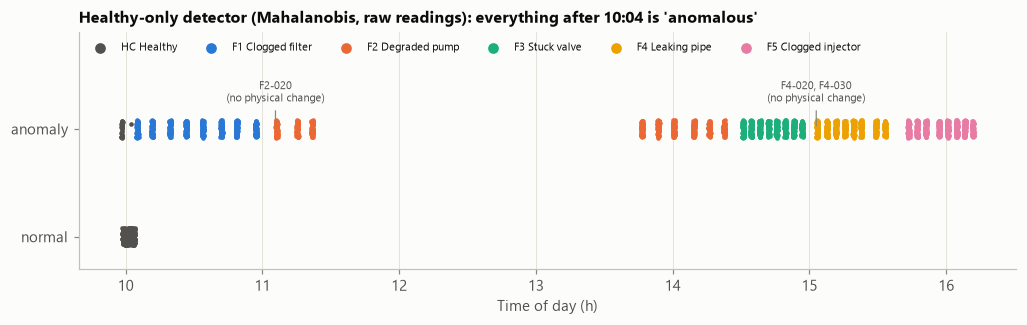

In [3]:
flag = flags_store[("raw readings", "Mahalanobis (shrinkage)")]
tod = w["clock"].dt.hour + w["clock"].dt.minute / 60 + w["clock"].dt.second / 3600
fig, ax = plt.subplots(figsize=(11, 2.8))
for c in config.CONDITIONS:
    m = w["condition"] == c
    ax.scatter(tod[m], flag[m] + np.random.default_rng(0).uniform(-0.08, 0.08, m.sum()), s=4,
               color=pl.CONDITION_COLORS[c], label=f"{c} {config.CONDITION_NAMES[c]}")
for label, r in [("F2-020", "F2-020"), ("F4-020, F4-030", "F4-020")]:
    t0 = tod[w["run_id"] == r].min()
    ax.annotate(f"{label}\n(no physical change)", (t0, 1.0), xytext=(0, 18), textcoords="offset points", ha="center",
                fontsize=7.5, color=pl.INK_2, arrowprops=dict(arrowstyle="-", color=pl.MUTED, lw=0.8))
ax.set_yticks([0, 1], ["normal", "anomaly"])
ax.set_ylim(-0.3, 1.9)
ax.set_xlabel("Time of day (h)")
ax.legend(ncol=6, fontsize=7.5, loc="upper left", markerscale=3)
ax.set_title("Healthy-only detector (Mahalanobis, raw readings): everything after 10:04 is 'anomalous'")
ax.grid(axis="y", visible=False)
pl.save(fig, "08_anomaly_detection")
plt.show()

**Every healthy-only detector flags every afternoon recording, including the three settings with no
physical change.** They detect the clear faults perfectly, but they would detect a healthy rig at
15:00 just as well. Two reasons, both about the data rather than the algorithms:

* the healthy reference covers **five minutes of one morning**; the healthy operating point then
  drifts through the day (pump delivery 1-3.5 % lower, suction ripple about 30 % lower, notebook 03);
* even within that morning, P1 trends with the tank level, so a detector fitted on five healthy runs
  flags 2-22 % of the sixth.

Physics residual features help only partly: they remove the effect of the operating point moving
along known laws, but not the drift in the laws themselves. A one-class model is only as good as the
variety of healthy behaviour it has seen. For the twin this means **the healthy reference must be
recorded across the conditions the rig meets in service** (temperatures, tank levels, times of day)
before unsupervised detection is worth deploying, which is requirement R1 and the data-collection
phase of the roadmap in `docs/task5_digital_twin_design.md`.

The alternative that does not need a day-wide healthy reference is to watch for **changes relative to
the recent past**, which is the next section.

## 2. Change detection on a stream

Consecutive recordings of each fault sweep were made a few minutes apart, so joining two of them gives
a stream with a known change at the join (one more step of degradation) and little drift across it.
Healthy-to-healthy joins (HC-1 to HC-2, and so on) are the controls: no alarm should fire.

Statistic: Hotelling T^2 of the six readings against the first 20 s of the stream (the shaded
reference window in the example below), with covariance
pooled from the healthy runs. Two detectors:
* **CUSUM** on T^2 (allowance k, threshold h);
* **Bayesian online change-point detection** (Adams and MacKay, 2007) on log(1 + T^2), alarm when the
  posterior probability of a change in the last 5 s exceeds a threshold. Niculita, Skaf and Jennions
  (2014) used Bayesian change-point detection on this same UAV fuel rig.

Both are tuned **on the healthy streams only**: the most sensitive setting that raises no alarm on
any healthy control.

In [4]:
hc = w[w["condition"] == "HC"]
dev = hc[RAW] - hc.groupby("run_id")[RAW].transform("mean")
inv_cov = np.linalg.inv(np.cov(dev.T.to_numpy()))
runs = list(w["run_id"].unique())
controls = [(f"HC-{i}", f"HC-{i + 1}") for i in range(1, 6)]
steps = [("HC-6", "F1-010")]
for f in config.FAULTS:
    rr = [r for r in runs if r.startswith(f)]
    steps += list(zip(rr[:-1], rr[1:]))
REF = 20


def t2_stream(a, b):
    x = pd.concat([w[w["run_id"] == a], w[w["run_id"] == b]])[RAW].to_numpy()
    return mo.hotelling_t2(x, x[:REF], inv_cov)


def run_cusum(pairs, k, h):
    out = []
    for a, b in pairs:
        al = mo.cusum(t2_stream(a, b), k, h, start=REF)
        out.append(np.nan if al is None else al - 60)
    return np.array(out)


def run_bocpd(pairs, thr, hazard=1 / 120):
    out = []
    for a, b in pairs:
        s = np.log1p(t2_stream(a, b))
        z = (s - s[:REF].mean()) / max(s[:REF].std(), 0.05)
        al = mo.bocpd_alarm(mo.bocpd(z, hazard=hazard), 5, thr, start=REF)
        out.append(np.nan if al is None else al - 60)
    return np.array(out)


tuning = []
for k in [12.6, 25, 50, 100, 200]:
    for h in [25, 50, 100, 200]:
        c = run_cusum(controls, k, h)
        tuning.append({"detector": "CUSUM", "setting": f"k={k}, h={h}", "k": k, "h": h,
                       "alarms on healthy controls": int(np.isfinite(c).sum())})
for thr in [0.5, 0.9, 0.99]:
    c = run_bocpd(controls, thr)
    tuning.append({"detector": "BOCPD", "setting": f"p>{thr}", "thr": thr,
                   "alarms on healthy controls": int(np.isfinite(c).sum())})
tuning = pd.DataFrame(tuning)
clean_cusum = tuning[(tuning["detector"] == "CUSUM") & (tuning["alarms on healthy controls"] == 0)].sort_values(["k", "h"]).iloc[0]
clean_b = tuning[(tuning["detector"] == "BOCPD") & (tuning["alarms on healthy controls"] == 0)].sort_values("thr").iloc[0]
print("Most sensitive clean settings (chosen on healthy controls only):",
      clean_cusum["setting"], "|", clean_b["setting"])

Most sensitive clean settings (chosen on healthy controls only): k=50, h=25 | p>0.9


In [5]:
res = pd.DataFrame({"stream": [f"{a} -> {b}" for a, b in steps],
                    "CUSUM alarm (s after join)": run_cusum(steps, clean_cusum["k"], clean_cusum["h"]),
                    "BOCPD alarm (s after join)": run_bocpd(steps, clean_b["thr"])})
res["step size (median T^2 after join)"] = [np.median(t2_stream(a, b)[60:]) for a, b in steps]
res.to_csv(config.TABLE_DIR / "08_change_detection.csv", index=False)
summ = {}
for col in ["CUSUM alarm (s after join)", "BOCPD alarm (s after join)"]:
    v = res[col]
    summ[col.split(" alarm")[0]] = {"false alarms before the join": int((v < 0).sum()),
                                     "missed steps": int(v.isna().sum()),
                                     "median delay (s)": float(v[v >= 0].median()),
                                     "max delay (s)": float(v[v >= 0].max())}
pd.DataFrame(summ)

,CUSUM,BOCPD
false alarms before the join,2.0,0.0
missed steps,0.0,2.0
median delay (s),0.0,0.0
max delay (s),0.0,1.0


In [6]:
res[res.isna().any(axis=1) | (res[["CUSUM alarm (s after join)", "BOCPD alarm (s after join)"]] < 0).any(axis=1)]

,stream,CUSUM alarm (s after join),BOCPD alarm (s after join),step size (median T^2 after join)
22,F3-070 -> F3-080,-26,0.0,662542.405
23,F4-020 -> F4-030,-13,NaN,113.880
29,F4-080 -> F4-090,0,NaN,94.737


* On the 36 real steps of degradation, both detectors fire **within about a second of the change**.
  The steps between settings are abrupt and large compared with the 1 s noise, so this is the easy
  case.
* The Bayesian detector raises **no false alarm before any join**; the CUSUM raises a couple, in
  recordings that start while the rig is still settling after the previous valve move (flow creeps by
  up to 1 % over the first minute, notebook 03 section 6). Settling transients are the main nuisance
  for change detection on this rig.
* The Bayesian detector misses two steps: **F4 20 % -> 30 %**, which has no physical change (the
  right answer), and **F4 80 % -> 90 %**, where the leak valve is nearly saturated and flow changes by
  only about 2 %.

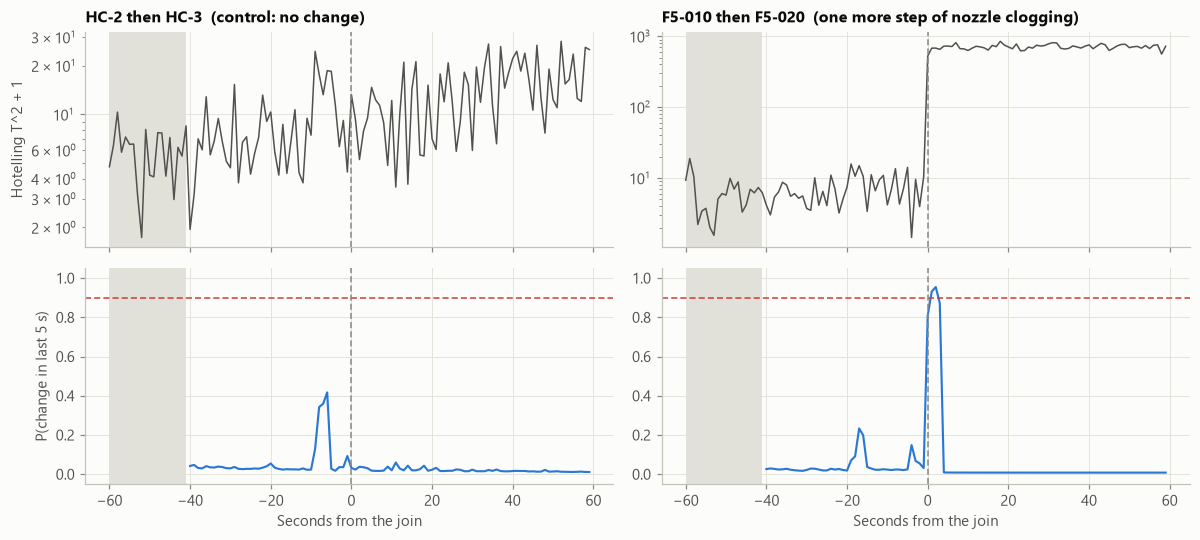

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5), sharex=True)
for col, (a, b) in enumerate([("HC-2", "HC-3"), ("F5-010", "F5-020")]):
    s = t2_stream(a, b)
    tt = np.arange(len(s)) - 60
    axes[0, col].semilogy(tt, s + 1, color=pl.INK_2, lw=1)
    axes[0, col].axvline(0, color=pl.MUTED, lw=1, ls=(0, (4, 2)))
    axes[0, col].set_title(f"{a} then {b}" + ("  (control: no change)" if a.startswith("HC") else "  (one more step of nozzle clogging)"))
    z = np.log1p(s)
    z = (z - z[:REF].mean()) / max(z[:REF].std(), 0.05)
    post = mo.bocpd(z, hazard=1 / 120)
    prob = post[:, :5].sum(axis=1)
    prob[:REF] = np.nan  # reference window: no decisions are taken here
    axes[1, col].plot(tt, prob, color=pl.SERIES[0], lw=1.4)
    for r_ in (0, 1):
        axes[r_, col].axvspan(tt[0], tt[REF - 1], color=pl.GRID, lw=0)
    axes[1, col].axhline(clean_b["thr"], color=pl.STATUS["critical"], lw=1, ls=(0, (4, 2)))
    axes[1, col].axvline(0, color=pl.MUTED, lw=1, ls=(0, (4, 2)))
    axes[1, col].set_ylim(-0.05, 1.05)
    axes[1, col].set_xlabel("Seconds from the join")
axes[0, 0].set_ylabel("Hotelling T^2 + 1")
axes[1, 0].set_ylabel("P(change in last 5 s)")
fig.tight_layout()
pl.save(fig, "08_change_detection_example")
plt.show()
#
# ### Gradual degradation
#
# Real filters clog and pumps wear over hours, not in one step. Using the calibrated network model
# (notebook 06), each fault is ramped smoothly from healthy over 10 min, 1 h and 6 h, with measurement
# noise drawn from the healthy runs. The CUSUM tuned above watches the stream; the question is how far
# the fault has progressed when the alarm fires.

In [8]:
rig = sm.RigModel.from_windows(w)
noise_cov = np.cov(dev.T.to_numpy())
ramps = {"F1": ("s_f", 1.0, 3.0), "F2": ("g_b", 0.0, 0.6), "F3": ("s_v", 1.0, 3.0), "F4": ("g_l", 0.0, 0.6),
         "F5": ("s_n", 1.0, 3.0)}
rng = np.random.default_rng(1)
grid_rows = []
for f, (par, lo, hi) in ramps.items():
    levels = np.linspace(lo, hi, 121)
    states = np.array([[rig.solve(**{par: v})[c] for c in RAW] for v in levels])
    q_h = rig.solve()["Q"]
    for minutes in (10, 60, 360):
        n = minutes * 60
        frac = np.clip((np.arange(n + 120) - 120) / n, 0, 1)  # 2 min healthy, then the ramp
        x = np.array([np.interp(frac * (len(levels) - 1), np.arange(len(levels)), states[:, j]) for j in range(6)]).T
        x = x + rng.multivariate_normal(np.zeros(6), noise_cov, size=len(x))
        al = mo.cusum(mo.hotelling_t2(x, x[:REF], inv_cov), clean_cusum["k"], clean_cusum["h"], start=REF)
        if al is None:
            grid_rows.append({"fault": f, "ramp to full over": f"{minutes} min", "detected after (min)": np.nan})
            continue
        lvl = lo + frac[al] * (hi - lo)
        q_at = np.interp(frac[al] * (len(levels) - 1), np.arange(len(levels)), states[:, 5])
        sev_txt = f"{lvl:.2f}x resistance" if par.startswith("s_") else f"{100 * rig.solve(**{par: lvl})['Ql' if par == 'g_l' else 'Qb'] / rig.solve(**{par: lvl})['Qp']:.1f} % flow lost"
        grid_rows.append({"fault": f, "ramp to full over": f"{minutes} min", "detected after (min)": (al - 120) / 60,
                          "fault level at detection": sev_txt, "delivered flow lost at detection (%)": 100 * (1 - q_at / q_h)})
grad = pd.DataFrame(grid_rows)
grad.to_csv(config.TABLE_DIR / "08_gradual_detection.csv", index=False)
grad

,fault,ramp to full over,detected after (min),fault level at detection,delivered flow lost at detection (%)
0,F1,10 min,0.633,1.13x resistance,0.251
1,F1,60 min,2.883,1.10x resistance,0.190
2,F1,360 min,16.750,1.09x resistance,0.184
3,F2,10 min,0.217,1.0 % flow lost,0.730
4,F2,60 min,1.050,0.8 % flow lost,0.590
5,F2,360 min,5.117,0.7 % flow lost,0.480
6,F3,10 min,0.100,1.02x resistance,0.081
7,F3,60 min,0.433,1.01x resistance,0.058
8,F3,360 min,2.500,1.01x resistance,0.056
9,F4,10 min,0.183,0.7 % flow lost,0.572


For slow degradation the useful number is not the delay but **how much degradation has accumulated
when the alarm fires**, and that is almost the same whatever the ramp speed: the detector fires once
the change in the readings exceeds a fixed multiple of the healthy noise. Blockages are caught at a
1-3 % of extra resistance for the valve and nozzle (about 10 % for the noisier filter) and bypass or
leak flow at under 1 % of the pump's output, while the delivered flow has fallen by less than 1 %. The caveat from section 1 applies with more force here: over
6 hours the real rig drifts by about as much (notebook 03), and this simulation adds noise but no
drift. Over long horizons a change detector cannot tell slow degradation from slow drift without an
extra measurement (temperature), which is the twin's requirement R1.

## 3. Kalman tracking of the health indicators

A Kalman filter turns the noisy 1 s residuals into a running estimate with an uncertainty band. Each
indicator (filter, pump, valve and nozzle residual, in units of its limit) is a random walk observed
with noise. The measurement noise comes from the healthy runs; the process noise is set by a chosen
response time tau (in windows): the filter moves a fraction 1 - exp(-1/tau) of the way to each new
reading. Over gaps between recordings the uncertainty grows with the gap, so the filter re-converges
quickly when a new recording starts.

In [9]:
ws = w.sort_values("clock").reset_index(drop=True)
t = (ws["clock"] - ws["clock"].iloc[0]).dt.total_seconds().to_numpy()
ECOLS = ["e_filter", "e_pump", "e_valve", "e_nozzle"]
r_var = ws[ws["condition"] == "HC"].groupby("run_id")[ECOLS].var().mean()
raw_iso = hy.isolate(ws[ECOLS].rename(columns=lambda c: c.replace("e_", "r_")))


def first_stable(pred, truth, n=5):
    ok = (pred == truth).to_numpy()
    for i in range(len(ok) - n + 1):
        if ok[i:i + n].all():
            return i
    return np.nan


hard = ["F1-010", "F1-020", "F2-030", "F3-010", "F3-020", "F4-040", "F5-010", "F5-020", "F5-030"]
kt_rows = []
smoothed = {}
for tau in (1.0, 2.0, 5.0, 10.0):
    est = pd.DataFrame({c.replace("e_", "r_"): mo.kalman_track(ws[c].to_numpy(), t, r_var[c], tau)[0] for c in ECOLS})
    iso = hy.isolate(est)
    smoothed[tau] = est
    row = {"response time tau (windows)": tau if tau > 1 else "none (raw windows)",
           "healthy windows misdiagnosed": float((iso[ws["condition"] == "HC"] != "HC").mean()) if tau > 1
           else float((raw_iso[ws["condition"] == "HC"] != "HC").mean())}
    use = iso if tau > 1 else raw_iso
    for r in hard:
        m = ws["run_id"] == r
        row[r] = float((use[m] == ws.loc[m, "condition"]).mean())
    kt_rows.append(row)
kt = pd.DataFrame(kt_rows).set_index("response time tau (windows)")
kt.to_csv(config.TABLE_DIR / "08_kalman_accuracy.csv")
kt.round(2)

,healthy windows misdiagnosed,F1-010,F1-020,F2-030,F3-010,F3-020,F4-040,F5-010,F5-020,F5-030
response time tau (windows),,,,,,,,,,
none (raw windows),0.0,0.48,1.0,1.0,0.22,1.0,1.0,0.0,0.58,1.0
2.0,0.0,0.63,1.0,1.0,0.22,1.0,1.0,0.0,0.73,1.0
5.0,0.0,0.62,1.0,1.0,0.28,1.0,1.0,0.0,0.70,1.0
10.0,0.0,0.50,1.0,1.0,0.33,1.0,1.0,0.0,0.63,1.0


Share of windows correctly diagnosed in the borderline recordings. A response time of about 2 windows
raises the accuracy on the hardest recordings (F1 10 %: 0.48 to about 0.6; F5 20 %: 0.58 to about 0.7)
without any extra mistakes on healthy data. Longer response times stop helping: the filter lags each
new recording and keeps the previous one's diagnosis for longer. Recordings with no physical fault
(F2 20 %, F4 20-30 %) and the drift case (F5 10 %) are not changed by smoothing, as they should not be:
smoothing reduces noise, it cannot add information.

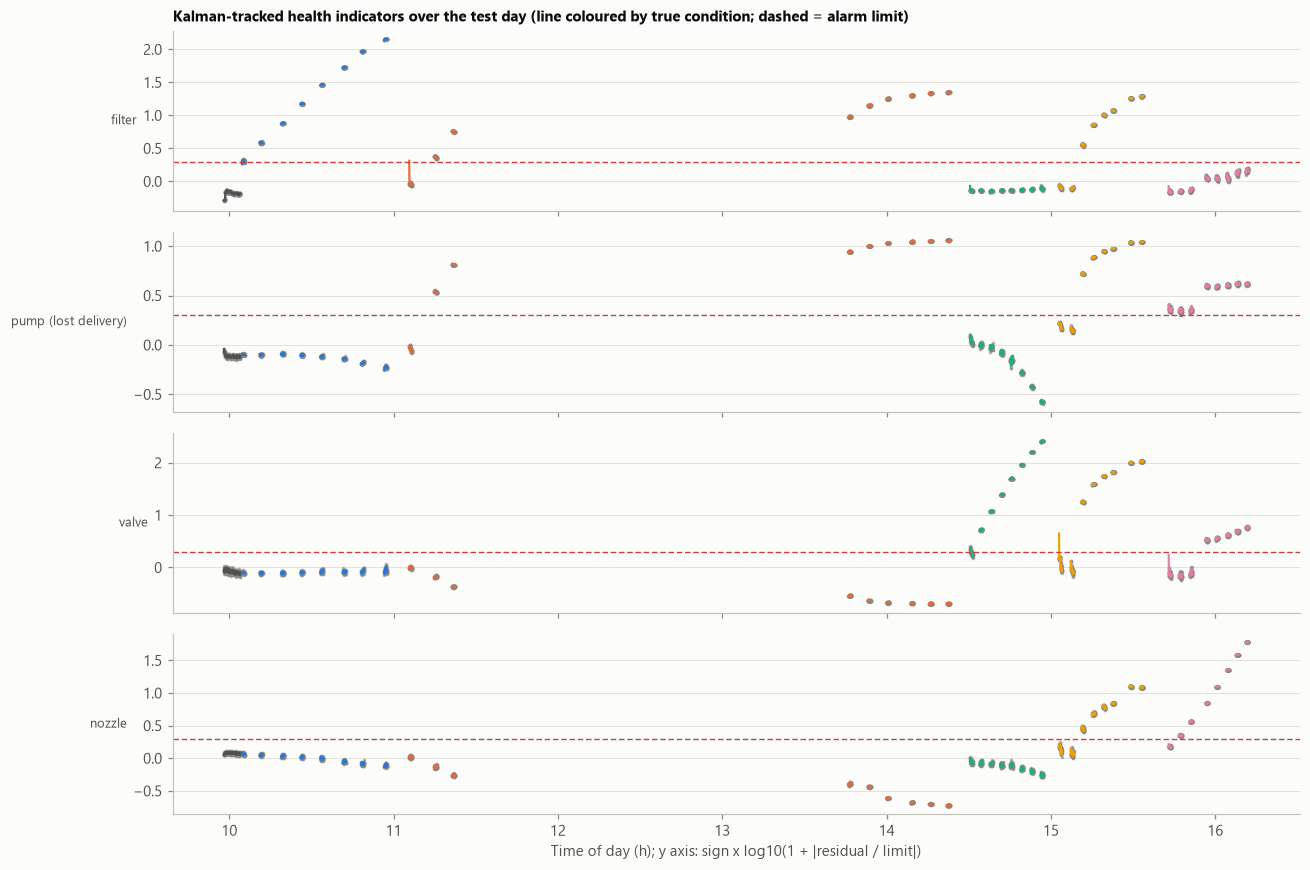

In [10]:
tau = 2.0
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
tod_s = ws["clock"].dt.hour + ws["clock"].dt.minute / 60 + ws["clock"].dt.second / 3600
names = {"e_filter": "filter", "e_pump": "pump (lost delivery)", "e_valve": "valve", "e_nozzle": "nozzle"}
for ax, c in zip(axes, ECOLS):
    x, sd = mo.kalman_track(ws[c].to_numpy(), t, r_var[c], tau)
    yy = np.sign(x) * np.log10(1 + np.abs(x))
    lo_ = np.sign(x - 2 * sd) * np.log10(1 + np.abs(x - 2 * sd))
    hi_ = np.sign(x + 2 * sd) * np.log10(1 + np.abs(x + 2 * sd))
    ax.scatter(tod_s, np.sign(ws[c]) * np.log10(1 + ws[c].abs()), s=2, color=pl.MUTED, alpha=0.5)
    for rid, g in ws.groupby("run_id", sort=False):
        idx = g.index
        ax.fill_between(tod_s[idx], lo_[idx], hi_[idx], color=pl.SERIES[0], alpha=0.25, lw=0)
        ax.plot(tod_s[idx], yy[idx], color=pl.CONDITION_COLORS[g["condition"].iloc[0]], lw=1.4)
    ax.axhline(np.log10(2), color=pl.STATUS["critical"], lw=0.9, ls=(0, (4, 2)))
    ax.set_ylabel(names[c], rotation=0, ha="right", va="center", fontsize=8.5)
    ax.grid(axis="x", visible=False)
axes[0].set_title("Kalman-tracked health indicators over the test day (line coloured by true condition; "
                  "dashed = alarm limit)", loc="left", fontsize=10)
axes[-1].set_xlabel("Time of day (h); y axis: sign x log10(1 + |residual / limit|)")
fig.tight_layout()
pl.save(fig, "08_kalman_tracking")
plt.show()

The tracked indicators give the twin a continuous, smoothed picture of each section's condition, with
an uncertainty band that narrows during steady running and widens over gaps. Two things a maintainer
can read off directly:

* each fault drives **its own indicator** (filter for F1, pump for F2, valve for F3, valve and pump for
  F4, nozzle for F5), the structure from notebook 03, now as a running estimate;
* the **pump indicator sits above its limit throughout the clogged-injector sweep** (15:43-16:11)
  although the pump and the line are healthy: the afternoon drift in pump delivery, the cause of the
  F5 10 % misdiagnosis. During the stuck-valve sweep it drifts negative instead, because one straight
  pump line fitted over the whole day is a compromise between morning and afternoon behaviour. A filter
  tuned to follow faults within seconds follows drift just as readily; separating the two needs a much
  slower second filter run on known-healthy periods, or an independent temperature measurement.
* the pump bypass (F2) and the leak (F4) also lift the filter indicator, because the pump draws extra
  flow through the filter to feed them; that is part of their signature, not an error.

## Summary

| Method | Needs fault labels? | What it achieved here | Limitation exposed |
|---|---|---|---|
| Healthy-only anomaly detection | no | clear faults 100 % | flags every afternoon window, including settings with no physical fault: the healthy reference spans 5 minutes |
| CUSUM / Bayesian change detection | no (tuned on healthy streams) | every real step caught within about 1 s; Bayesian detector with no false alarms, missing only a step with no physical change and one 2 % step | settling transients after valve moves; slow drift indistinguishable from slow degradation |
| Gradual degradation (simulated) | no | alarm at 1-3 % extra resistance (filter about 10 %) or under 1 % lost flow, whatever the ramp speed | simulation has no drift |
| Kalman tracking | no | smoother indicators; borderline recordings 10-15 points more accurate | tracks drift as readily as faults |

Together with notebooks 04-07 the conclusion is consistent: the algorithms are not the bottleneck.
What limits detection on this rig is **what the healthy reference covers** and **the missing
temperature measurement**, which is why those top the twin's requirements.